# MATH840 Final project: 48 hours of generation

**Liliia Yaroshenko**

This notebook produces `YAROSHENKO_project.csv` from `train.csv` and `weather_forecast.csv`: an hourly
point forecast and a 95% prediction interval for the 48 hours after 27 October 2026, 00:00.

**Final model**
- **Point forecast in daylight hours:** 0.75 × the median of Timestral-209M (a pretrained time-series model
  from Mistral AI), conditioned on the weather as known covariates, + 0.25 × a LightGBM/seasonal-naive blend.
- **Point forecast at night:** Timestral's 45th percentile.
- **95% interval:** Timestral's own 2.5% and 97.5% quantiles, shifted with the point forecast.

Section 5 backtests every model on the last 26 windows of 48 hours. The report follows in section 7.

Runtime: about 2 minutes on a Colab GPU. On a CPU the backtest takes about 15 minutes; set `N_EVAL` lower to
make it faster.

## 0. Setup

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("timestral") is None:      # Timestral is installed from GitHub (not on PyPI)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/mistralai/timestral.git"], check=True)

import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import torch
from timestral import TimestralForecaster

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 140, "display.precision", 3)
torch.manual_seed(0)

SURNAME = "YAROSHENKO"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| torch", torch.__version__, "| lightgbm", lgb.__version__)

device: cpu | torch 2.15.0+cpu | lightgbm 4.7.0


In [2]:
NEEDED = ["train.csv", "weather_forecast.csv"]
if not all(Path(f).exists() for f in NEEDED):
    try:
        from google.colab import files
        files.upload()                       # choose both files at once
    except ImportError:
        raise FileNotFoundError(f"Put {NEEDED} next to this notebook.")

data = pd.read_csv("train.csv", parse_dates=["ds"])
weather_fc = pd.read_csv("weather_forecast.csv", parse_dates=["ds"])

H, M = 48, 24
FUTURE = weather_fc["ds"]
WX = ["cloud_cover", "temperature", "wind_speed", "pressure", "humidity", "daylight", "air_density"]

assert len(FUTURE) == H and FUTURE.iloc[0] == data["ds"].iloc[-1] + pd.Timedelta(hours=1)
assert (data["ds"].diff().dropna() == pd.Timedelta(hours=1)).all(), "the history has gaps"
print(f"history: {len(data)} hours, {data['ds'].min()} to {data['ds'].max()}")
print(f"forecasting: {FUTURE.iloc[0]} to {FUTURE.iloc[-1]}")

history: 33480 hours, 2023-01-01 01:00:00 to 2026-10-27 00:00:00
forecasting: 2026-10-27 01:00:00 to 2026-10-29 00:00:00


## 1. What is in the series

The checks below drove the model choices:
1. **The level has grown 3–5 times since 2023**, so old history describes a smaller portfolio.
2. **A daily cycle that peaks at midday** looks like solar generation.
3. **Night output rises with wind speed**, which looks like wind generation.
4. **The last week before the cutoff fell sharply.**

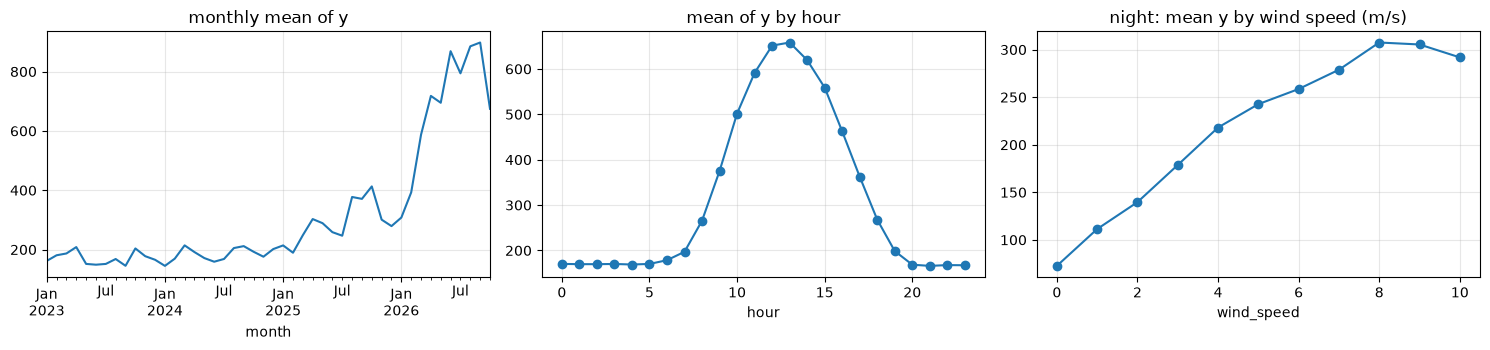

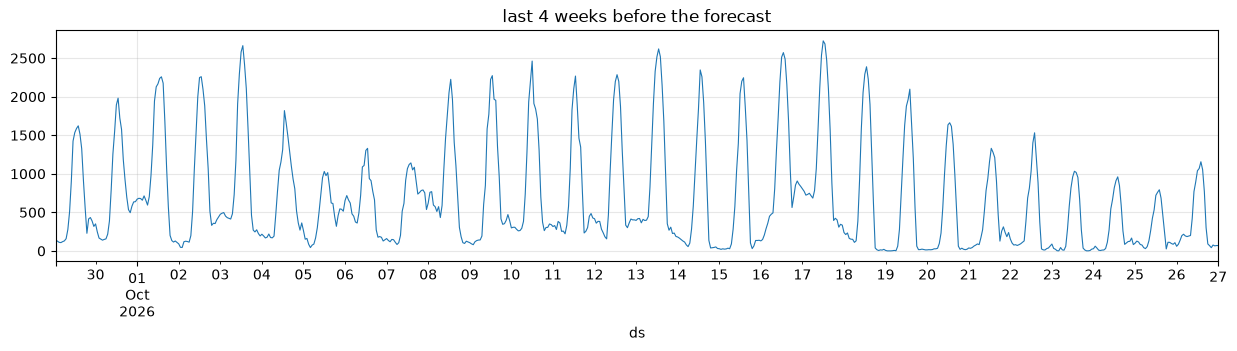

share of hours with y < 20 (last 90 days): 0.021


In [3]:
d = data.assign(hour=data.ds.dt.hour, month=data.ds.dt.to_period("M"))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
d.groupby("month").y.mean().plot(ax=ax[0], title="monthly mean of y")
d.groupby("hour").y.mean().plot(ax=ax[1], marker="o", title="mean of y by hour")
night = d[d.daylight == 0]
night.groupby(night.wind_speed.clip(upper=10)).y.mean().plot(ax=ax[2], marker="o", title="night: mean y by wind speed (m/s)")
plt.tight_layout(); plt.show()

last = data[data.ds > data.ds.max() - pd.Timedelta(days=28)]
last.set_index("ds").y.plot(figsize=(15, 3), title="last 4 weeks before the forecast", lw=0.8); plt.show()
print("share of hours with y < 20 (last 90 days):",
      round((data[data.ds > data.ds.max() - pd.Timedelta(days=90)].y < 20).mean(), 3))

## 2. Scores and the benchmark (from the template)

In [4]:
def rmse(actual, forecast) -> float:
    return float(np.sqrt(np.mean((np.asarray(actual) - np.asarray(forecast)) ** 2)))


def mape(actual, forecast) -> float:
    actual, forecast = np.asarray(actual, float), np.asarray(forecast, float)
    return float(np.mean(np.abs((actual - forecast) / actual)) * 100)


def winkler(actual, lower, upper, alpha: float = 0.05) -> float:
    actual, lower, upper = (np.asarray(a, float) for a in (actual, lower, upper))
    below = np.clip(lower - actual, 0, None)
    above = np.clip(actual - upper, 0, None)
    return float(np.mean((upper - lower) + 2 / alpha * (below + above)))


def score(actual, forecast, lower, upper) -> dict:
    inside = (np.asarray(actual) >= lower) & (np.asarray(actual) <= upper)
    return {"RMSE": rmse(actual, forecast), "MAPE": mape(actual, forecast),
            "Winkler": winkler(actual, lower, upper), "coverage": float(inside.mean())}


def snaive(history: np.ndarray, h: int = H, m: int = M):
    history = np.asarray(history, float)
    point = np.array([history[-m + (i % m)] for i in range(h)])
    sigma = np.std(history[m:] - history[:-m], ddof=1)
    k = np.arange(h) // m
    half = 1.96 * sigma * np.sqrt(k + 1)
    return point, np.clip(point - half, 0, None), point + half

## 3. Models

### 3a. LightGBM blend (the Session 1 model)
Two LightGBM models (one on `y`, one on `log(1+y)`), each split into a day-1 model that may use lag 24 and a
day-2 model whose shortest lag is 48. Every feature is therefore known when the forecast is made. The blend
averages both models with the seasonal naive.

In [5]:
LGB_PARAMS = dict(objective="regression", learning_rate=0.05, num_leaves=31, min_data_in_leaf=40,
                  bagging_fraction=0.8, bagging_freq=1, feature_fraction=0.8, seed=0, verbose=-1)


def make_feats(df, min_lag, log):
    tf = np.log1p if log else (lambda s: s)
    X = pd.DataFrame({"hour": df["ds"].dt.hour, "dow": df["ds"].dt.dayofweek,
                      "doy": df["ds"].dt.dayofyear, **{c: df[c] for c in WX}})
    lags = (24, 48, 72, 168, 336) if min_lag == 24 else (48, 72, 168, 336)
    for L in lags:
        X[f"lag{L}"] = tf(df["y"].shift(L))
    X["mean_7d"] = tf(df["y"].shift(min_lag).rolling(168).mean())
    X["mean_1d"] = tf(df["y"].shift(min_lag).rolling(24).mean())
    return X


def lgb_fit_pred(hist, future, min_lag, log):
    full = pd.concat([hist, future.assign(y=np.nan)], ignore_index=True)
    X = make_feats(full, min_lag, log); n = len(hist)
    ok = X.iloc[:n].notna().all(axis=1)
    target = np.log1p(hist["y"][ok]) if log else hist["y"][ok]
    m = lgb.train(LGB_PARAMS, lgb.Dataset(X.iloc[:n][ok], target), num_boost_round=400)
    p = m.predict(X.iloc[n:])
    return np.expm1(p) if log else np.clip(p, 0, None)


def lgb_two_model(hist, future, log):
    day2 = lgb_fit_pred(hist, future, 48, log)
    day1 = lgb_fit_pred(hist, future.iloc[:24], 24, log)
    return np.r_[day1, day2[24:]]


def lgb_blend(hist, future):
    sn = snaive(hist["y"].to_numpy(float))[0]
    return (lgb_two_model(hist, future, True) + lgb_two_model(hist, future, False) + sn) / 3

### 3b. Timestral-209M with the weather as known covariates
[Timestral](https://mistral.ai/news/timestral/) is Mistral AI's open-weight time-series foundation model.
It is pretrained, so nothing is fitted on this series. It reads the last `CTX` hours of `y` and of the weather,
plus the weather over the horizon, and returns 21 quantiles (0.01 to 0.99) for each hour.

- In the backtest, the weather over the horizon is the **actual** weather.
- In the submission, it is the **forecast** from `weather_forecast.csv`.

In [6]:
CTX = 8192                                     # hours of context (~11 months)
ts_model = TimestralForecaster.from_pretrained("mistralai/Timestral-209M", device=DEVICE)
LEVELS = list(ts_model.quantile_levels)
print("quantile levels:", LEVELS)


def timestral_quantiles(hists, futures, batch=8):
    # hists / futures: lists of DataFrames -> array (n, 48, 21); windows are batched
    ctxs = np.stack([h["y"].to_numpy(float)[-CTX:] for h in hists])
    covs = np.stack([pd.concat([h[WX].iloc[-CTX:], f[WX]]).to_numpy(float).T for h, f in zip(hists, futures)])
    out = []
    for b in range(0, len(ctxs), batch):
        f = ts_model.forecast(ctxs[b:b + batch], prediction_length=H, known_covariates=covs[b:b + batch])
        out.append(f.quantiles.cpu().numpy()[:, 0])
    return np.concatenate(out)


def q_at(q, level):
    # interpolate the (48, 21) quantile array at any level, e.g. 0.025
    return np.array([np.interp(level, LEVELS, row) for row in q])

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00, 951.52it/s]

quantile levels: [0.01, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99]


### 3c. The final combination
- **Daylight hours:** 0.75 × Timestral median + 0.25 × LightGBM blend. On its own, Timestral overshot in the
  late-October drop, and the blend handled those windows better.
- **Night hours:** Timestral's 45% quantile. Night values are small, and MAPE divides by the actual value, so a
  slightly low forecast costs little RMSE and saves a lot of MAPE.
- **Interval:** Timestral's 2.5% and 97.5% quantiles, shifted by the change in the point forecast. They are
  clipped at 0, and the forecast always lies inside.

In [7]:
W_BLEND_DAY, NIGHT_Q = 0.25, 0.45


def combine(q, blend, daylight):
    med = q_at(q, 0.5)
    point = np.where(daylight == 1, (1 - W_BLEND_DAY) * med + W_BLEND_DAY * blend, q_at(q, NIGHT_Q))
    shift = point - med
    lower = np.minimum(np.clip(q_at(q, 0.025) + shift, 0, None), point)
    upper = np.maximum(q_at(q, 0.975) + shift, point)
    return point, lower, upper


def final_forecast(hist, future):
    q = timestral_quantiles([hist], [future])[0]
    return combine(q, lgb_blend(hist, future), future["daylight"].to_numpy())

## 4. Backtest design
- **Windows:** the last `N_EVAL` windows of 48 hours (default 26: 3 Sep to 27 Oct). Each model is trained or
  conditioned only on the hours before its window.
- **Scoring:** the full 48 hours, and the **second day** separately, because the private ranking uses only
  hours 25–48.
- **Benchmark:** the seasonal naive with the template's interval.
- **Day-1 and day-2 LightGBM:** each model's shortest lag (24 or 48) keeps every feature known at forecast time.

In [8]:
N_EVAL = 26
wins_ = []
for w in range(N_EVAL, 0, -1):
    end = len(data) - (w - 1) * H
    wins_.append((data.iloc[:end - H], data.iloc[end - H:end]))

Q_bt = timestral_quantiles([h for h, _ in wins_], [f.drop(columns="y") for _, f in wins_])
BL_bt = [lgb_blend(h, f.drop(columns="y")) for h, f in wins_]
print("backtest forecasts done:", Q_bt.shape)

backtest forecasts done: (26, 48, 21)


In [9]:
rows = []
for i, (hist, fut) in enumerate(wins_):
    a, day = fut["y"].to_numpy(float), fut["daylight"].to_numpy()
    sn = snaive(hist["y"].to_numpy(float))
    ts_only = (q_at(Q_bt[i], .5), np.clip(q_at(Q_bt[i], .025), 0, None), q_at(Q_bt[i], .975))
    models = {"seasonal naive": sn,
              "LightGBM blend (point only, naive interval)": (BL_bt[i], *sn[1:]),
              "Timestral-209M + weather": ts_only,
              "FINAL": combine(Q_bt[i], BL_bt[i], day)}
    for name, (f, lo, up) in models.items():
        for part, sl in (("48h", slice(0, 48)), ("day 2", slice(24, 48))):
            s = score(a[sl], f[sl], lo[sl], up[sl])
            s["skill"] = s["RMSE"] / rmse(a[sl], sn[0][sl])
            rows.append(dict(window=f"{fut.ds.iloc[0]:%d %b}", model=name, part=part, **s))
bt = pd.DataFrame(rows)

summary = bt.groupby(["part", "model"], sort=False)[["RMSE", "MAPE", "Winkler", "coverage", "skill"]].mean()
summary["RMSE wins vs naive"] = bt.groupby(["part", "model"], sort=False)["skill"].apply(lambda s: f"{(s < 1).sum()}/{len(s)}")
summary.round(3)

,,RMSE,MAPE,Winkler,coverage,skill,RMSE wins vs naive
part,model,,,,,,
48h,seasonal naive,306.909,203.788,2391.783,0.749,1.000,0/26
day 2,seasonal naive,319.738,155.970,2242.775,0.806,1.000,0/26
48h,"LightGBM blend (point only, naive interval)",250.189,149.957,2391.783,0.749,0.839,24/26
day 2,"LightGBM blend (point only, naive interval)",259.523,124.450,2242.775,0.806,0.847,20/26
48h,Timestral-209M + weather,188.093,62.791,841.332,0.962,0.665,24/26
day 2,Timestral-209M + weather,195.950,59.434,890.383,0.962,0.679,21/26
48h,FINAL,190.845,56.090,843.778,0.959,0.661,24/26
day 2,FINAL,198.782,55.045,910.484,0.958,0.678,22/26


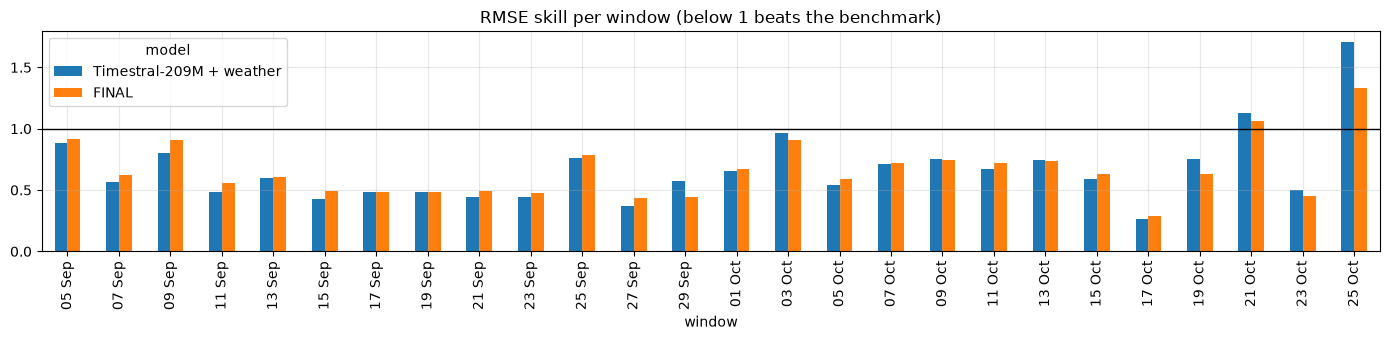

In [10]:
# per-window RMSE skill of the final model (below 1 = beats the benchmark)
per_w = bt[(bt.part == "48h")].pivot(index="window", columns="model", values="skill")[["Timestral-209M + weather", "FINAL"]]
ax = per_w.reindex(bt.window.unique()).plot(kind="bar", figsize=(14, 3.5), title="RMSE skill per window (below 1 beats the benchmark)")
ax.axhline(1, color="black", lw=1); plt.tight_layout(); plt.show()

## 5. Diagnostics of the final model on the backtest

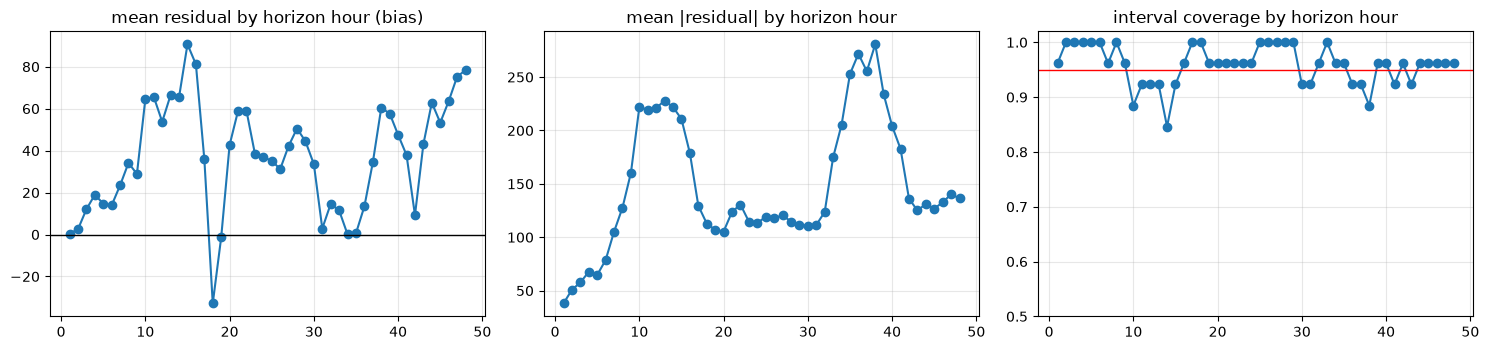

overall coverage 0.959 | day 1 0.960 | day 2 0.958
mean residual 37.0 (positive = forecast too low)


In [11]:
res, cover_h = [], []
for i, (hist, fut) in enumerate(wins_):
    f, lo, up = combine(Q_bt[i], BL_bt[i], fut["daylight"].to_numpy())
    a = fut["y"].to_numpy(float)
    res.append(a - f); cover_h.append((a >= lo) & (a <= up))
res, cover_h = np.array(res), np.array(cover_h)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].plot(range(1, 49), res.mean(0), marker="o"); ax[0].axhline(0, color="black", lw=1)
ax[0].set_title("mean residual by horizon hour (bias)")
ax[1].plot(range(1, 49), np.abs(res).mean(0), marker="o"); ax[1].set_title("mean |residual| by horizon hour")
ax[2].plot(range(1, 49), cover_h.mean(0), marker="o"); ax[2].axhline(0.95, color="red", lw=1)
ax[2].set_title("interval coverage by horizon hour"); ax[2].set_ylim(0.5, 1.02)
plt.tight_layout(); plt.show()
print(f"overall coverage {cover_h.mean():.3f} | day 1 {cover_h[:, :24].mean():.3f} | day 2 {cover_h[:, 24:].mean():.3f}")
print(f"mean residual {res.mean():.1f} (positive = forecast too low)")

## 6. Submission

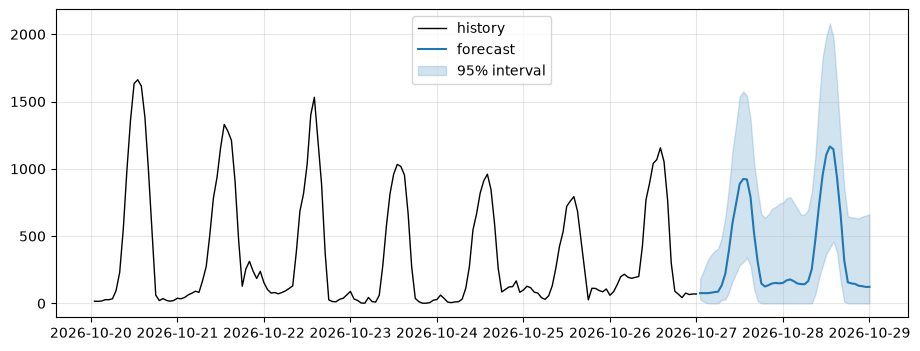

In [12]:
forecast, lower_95, upper_95 = final_forecast(data, weather_fc)

fig, ax = plt.subplots()
ax.plot(data["ds"].iloc[-7 * M:], data["y"].iloc[-7 * M:], color="black", lw=1, label="history")
ax.plot(FUTURE, forecast, color="tab:blue", label="forecast")
ax.fill_between(FUTURE, lower_95, upper_95, color="tab:blue", alpha=0.2, label="95% interval")
ax.legend(); plt.show()

In [13]:
def check_submission(sub: pd.DataFrame) -> None:
    assert list(sub.columns) == ["ds", "forecast", "lower_95", "upper_95"], "wrong columns"
    assert len(sub) == H, f"need {H} rows, got {len(sub)}"
    assert (pd.to_datetime(sub["ds"]).to_numpy() == FUTURE.to_numpy()).all(), "the hours do not match FUTURE"
    assert sub[["forecast", "lower_95", "upper_95"]].notna().all().all(), "missing values"
    assert (sub["lower_95"] >= 0).all(), "a lower bound is negative"
    assert (sub["lower_95"] <= sub["forecast"]).all() and (sub["forecast"] <= sub["upper_95"]).all(), \
        "the forecast must lie inside its interval"
    print("format OK")


submission = pd.DataFrame({"ds": FUTURE.dt.strftime("%Y-%m-%d %H:%M:%S"), "forecast": forecast,
                           "lower_95": lower_95, "upper_95": upper_95})
check_submission(submission)
FILE = f"{SURNAME}_project.csv"
submission.to_csv(FILE, index=False)
print("saved", FILE)

format OK
saved YAROSHENKO_project.csv


## 7. Report

### What is in the series?
- **Two daily regimes.** Output peaks at midday (mean ~650 at 12–13h) and stays flat at night (~170), which
  looks like solar generation. Night output rises with wind speed (mean 73 at 0 m/s, ~300 at 8 m/s), which
  looks like wind generation. So the weather matters, and it matters differently by day and by night.
- **Strong growth.** Monthly means are ~150–200 in 2023 and ~700–900 in mid-2026, so the portfolio grew 3–5
  times. Old history describes a smaller system. Lag and level features help the models more than the
  calendar does.
- **A sharp drop just before the cutoff.** Daily peaks fell from ~2,500 (mid-October) to ~1,000 in the last
  week. This is the hardest moment to forecast from: every model that adapts slowly overshoots.
- **Tiny values at night.** 3–8% of night hours are below 20. In the backtest, the 2.9% of hours with an
  actual value below 20 produced 61% of the total absolute percentage error. MAPE is driven by a handful of
  night hours.

**How this shaped the model:**
- The weather enters as **known covariates over the horizon**, which is the single biggest gain (see below).
- Day and night get **different point rules**.
- The interval width **follows the level and the hour** instead of being a constant band.

I used `weather_forecast.csv` for the submission. Leaving it out loses most of the accuracy: Timestral
without the weather has RMSE 267 against 188 with it. The backtest uses the actual weather, so the real
errors will be larger; the stress test below estimates by how much.

### How did I check the forecast before submitting it?
- **Rolling-origin backtest.** The last 26 non-overlapping windows of 48 hours (3 Sep to 27 Oct 2026). Every
  model sees only the hours before its window.
- **Day 2 scored separately**, because the private ranking uses hours 25–48 only.
- **Wins counted** as the number of windows in which the RMSE beats the seasonal naive. A single window is
  misleading: the template's validation window (25–27 Oct) was the calmest of all, and the Session 1 blend
  looked twice as good there as on average.

| Model (26 windows, 48 h) | RMSE | MAPE | Winkler | Coverage | Skill | Wins |
|---|---|---|---|---|---|---|
| Seasonal naive (benchmark) | 307 | 204 | 2392 | 0.75 | 1.00 | – |
| LightGBM variants (best of 9) | 240 | 103–177 | ≈1150 | ≈0.91 | 0.83 | 20/26 |
| Session 1 blend, as submitted | 252 | 151 | 1914 | 0.91 | 0.84 | 24/26 |
| Timestral-209M, no weather | 267 | 155 | 1041 | 0.96 | 0.93 | 20/26 |
| Timestral-209M + weather | 188 | 63 | 841 | 0.96 | 0.66 | 24/26 |
| **Final** (section 3c) | **191** | **56** | **844** | 0.96 | **0.66** | 24/26 |
| Final, day 2 only | 199 | 55 | 910 | 0.96 | 0.68 | 22/26 |

**Two further checks:**
- **Late-October drop.** In the last 4 windows (19–27 Oct), Timestral alone lost to the benchmark (mean
  skill 1.02), while the LightGBM blend won all 4. Mixing 25% of the blend into the daylight hours brings
  the last-4 skill to 0.87 and costs nothing on average.
- **Weather-forecast errors.** I re-ran Timestral with noise added to the horizon weather: temperature ±1.5 °C,
  wind ±1 m/s, humidity ±5%, pressure ±1 mm and cloud ±0.25, all doubled on day 2. The size of the noise is
  my assumption, because the real forecast error is unknown. Day-2 RMSE rose from 196 to 236 (moderate
  noise) and to 264 (twice that), and day-2 Winkler from 890 to 1200 and 1624. It still beats the benchmark
  (day-2 RMSE 320, Winkler 2243) in both cases, but the real advantage is smaller than the backtest shows.

### How good is the interval?

| Interval on the same Timestral point forecast | Winkler 48h | Winkler day 2 | Coverage |
|---|---|---|---|
| Timestral's own 2.5–97.5% quantiles (used) | **841** | **890** | 0.96 |
| Timestral 5–95%, conformalised (scaled) on 14 earlier windows | 873 | 935 | 0.95 |
| Timestral 1–99% | 876 | 934 | 0.98 |
| Additive conformal residual quantiles | 1062 | 1132 | 0.92 |
| Session 1 method: log-residual quantiles (on the blend) | 1914 | 2021 | 0.91 |

- **The Session 1 interval was the main weakness.** On the public leaderboard my RMSE ranked about 5th, but
  my Winkler (941) ranked about 25th, with 100% coverage. The log-scale (multiplicative) interval became very
  wide at the midday peaks.
- **Timestral's quantiles are calibrated out of the box.** Coverage is 0.96 against the 0.95 target, and
  conformal adjustment made them slightly worse, so I use them as they are.
- **Coverage by horizon hour** is plotted in section 5. The final interval covers 0.959 of the backtest hours (day 1 0.960, day 2 0.958).
- **With weather errors**, the quantiles widen and coverage rises to 0.99–1.00, so the interval errs on the
  safe side: the ×40 penalty for a miss is avoided.

### What is left, and what did not work?

**Residuals** (section 5). The mean residual is +37, so the final forecast is slightly too low on average. The bias plot shows where along the horizon this happens. The largest errors are at the midday peaks on cloudy, changeable days
and right after level shifts such as the late-October drop.

**What did not work:**

| Approach | Result | Why I dropped it |
|---|---|---|
| A shorter Timestral context (1024–4096 h), to adapt to the drop | worse everywhere, including the drop (last-4 skill 1.31–1.36) | the model needs a long context to learn the daily and weather patterns |
| LightGBM variants: target relative to the 7-day level, physics features (wind³·air density, daylight·(1 − cloud)), training on the last 365 days | all within RMSE 240–258, so no real gain | the extra features add little over lags + weather |
| Adding LightGBM to every hour | MAPE 63 → 83 | the LightGBM-on-`y` model is too high at night |
| A 50/50 Timestral/blend mix | RMSE 188 → 206 | too much weight on the weaker model |
| Widening intervals (×1.3, ×1.6 on the log scale) | Winkler up 20–60% | coverage rose, but the width cost more than the misses saved |
| Choosing a model on the single template window | misleading | that window was unusually calm |
| Re-scaling the interval by the coverage of the last 3–14 windows (adaptive conformal) | Winkler 847 → 867–970, also worse on the most recent windows | the scale factor follows noise more than real changes in volatility |

**What is left:**
- **Real weather-forecast errors.** A model trained or conditioned on historical *forecasts* rather than
  actual weather would be more honest, but those forecasts are not available.
- **Faster reaction to level shifts.** A model that tracks the level could help, for example by re-scaling
  the context by the last week's level.
- **Fine-tuning Timestral on this series**, instead of zero-shot use.